# Étape 1 – Chargement propre des données

**Objectif :** charger le dataset *CS:GO Round Snapshots* de façon fiable et reproductible, puis vérifier sa qualité avant toute analyse.

**Ce qui change par rapport à l'ancien notebook :**

| Ancien notebook | Nouvelle version |
| --- | --- |
| Parsing ARFF à la main, dans le notebook | Fonction `load_data()` dans `src/data.py`, réutilisable partout |
| Fichiers `dataset.txt` et `df.csv` créés n'importe où | Données rangées dans `data/raw/` |
| Cible créée avec `cat.codes` (dépend de l'ordre alphabétique) | Cible explicite : `t_win = 1` si `round_winner == "T"` |
| Aucune vérification | Rapport de qualité : lignes, colonnes, manquants, doublons, équilibre |

Chaque ligne du dataset est une **photo** d'un round, prise environ toutes les 20 secondes pendant des matchs de haut niveau.

## 1. Imports

Le notebook est dans `notebooks/`. On ajoute le dossier parent au chemin Python pour pouvoir importer le code de `src/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_DATA_PATH, SEED, TARGET
from src.data import load_data, check_data, print_report

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__)

pandas 2.3.3


## 2. Chargement

La première exécution télécharge le fichier depuis OpenML (environ 1 minute) et crée `data/raw/csgo_round_snapshots.csv`. Les fois suivantes, le CSV est lu directement.

In [2]:
df = load_data()
print(f"{df.shape[0]:,} lignes x {df.shape[1]} colonnes")
df.head()

122,410 lignes x 98 colonnes


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,ct_defuse_kits,ct_players_alive,...,t_weapon_tec9,ct_grenade_hegrenade,t_grenade_hegrenade,ct_grenade_flashbang,t_grenade_flashbang,ct_grenade_smokegrenade,t_grenade_smokegrenade,ct_grenade_incendiarygrenade,t_grenade_incendiarygrenade,ct_grenade_molotovgrenade,t_grenade_molotovgrenade,ct_grenade_decoygrenade,t_grenade_decoygrenade,round_winner,t_win
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT,0
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,1.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,CT,0
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,CT,0
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,1.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT,0
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,1.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT,0


## 3. Rapport de qualité

Les lignes marquées `OK` correspondent à ce qui est attendu. Une ligne `!!` signale un problème à regarder.

In [3]:
report = check_data(df)
print_report(report)


========== Rapport de qualité des données ==========
OK Lignes            : 122,410 (attendu 122,410)
OK Colonnes          : 98 (attendu 98, t_win compris)
OK Colonnes clés     : toutes présentes
OK Valeurs manquantes: 0
   Lignes en double  : 4,962 (4.1%) -> gardées pour l'instant, analysées à l'étape 3
   Victoires T       : 51.0%
   Victoires CT      : 49.0%
   Cartes            : 8 -> de_cache, de_dust2, de_inferno, de_mirage, de_nuke, de_overpass, de_train, de_vertigo
   Types de colonnes : {'float64': 94, 'category': 2, 'boolean': 1, 'int64': 1}



## 4. Types des colonnes

On vérifie que chaque colonne a le bon type : nombres pour les quantités, catégorie pour `map` et `round_winner`, booléen pour `bomb_planted`.

In [4]:
df.dtypes.value_counts()

float64     94
category     1
boolean      1
category     1
int64        1
Name: count, dtype: int64

In [5]:
df[["map", "round_winner", "bomb_planted", TARGET]].dtypes

map             category
round_winner    category
bomb_planted     boolean
t_win              int64
dtype: object

## 5. Statistiques descriptives des variables principales

On regarde les valeurs minimales et maximales pour repérer des valeurs impossibles (par exemple plus de 5 joueurs vivants, ou une santé d'équipe au-dessus de 500).

In [6]:
main_cols = ["time_left", "ct_score", "t_score", "ct_health", "t_health",
             "ct_armor", "t_armor", "ct_money", "t_money",
             "ct_players_alive", "t_players_alive"]
df[main_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
time_left,122410.0,97.9,54.5,0.0,54.9,94.9,166.9,175.0
ct_score,122410.0,6.7,4.8,0.0,3.0,6.0,10.0,32.0
t_score,122410.0,6.8,4.8,0.0,3.0,6.0,10.0,33.0
ct_health,122410.0,412.1,132.3,0.0,350.0,500.0,500.0,500.0
t_health,122410.0,402.7,139.9,0.0,322.0,500.0,500.0,600.0
ct_armor,122410.0,314.1,171.0,0.0,194.0,377.0,486.0,500.0
t_armor,122410.0,298.4,174.6,0.0,174.0,334.0,468.0,500.0
ct_money,122410.0,9789.0,11215.0,0.0,1300.0,5500.0,14600.0,80000.0
t_money,122410.0,11241.0,12162.8,0.0,1550.0,7150.0,18000.0,80000.0
ct_players_alive,122410.0,4.3,1.2,0.0,4.0,5.0,5.0,5.0


In [7]:
# Contrôles de cohérence : chaque condition doit donner 0 ligne
checks = {
    "plus de 5 joueurs vivants (CT)": (df["ct_players_alive"] > 5).sum(),
    "plus de 5 joueurs vivants (T)": (df["t_players_alive"] > 5).sum(),
    "santé d'équipe > 500 (CT)": (df["ct_health"] > 500).sum(),
    "santé d'équipe > 500 (T)": (df["t_health"] > 500).sum(),
    "temps restant négatif": (df["time_left"] < 0).sum(),
    "argent négatif": ((df["ct_money"] < 0) | (df["t_money"] < 0)).sum(),
}
pd.Series(checks, name="nombre de lignes")

plus de 5 joueurs vivants (CT)    0
plus de 5 joueurs vivants (T)     1
santé d'équipe > 500 (CT)         0
santé d'équipe > 500 (T)          1
temps restant négatif             0
argent négatif                    0
Name: nombre de lignes, dtype: int64

## 6. Équilibre de la cible

Si une classe était très majoritaire, l'accuracy seule serait trompeuse. Ici on s'attend à un dataset à peu près équilibré.

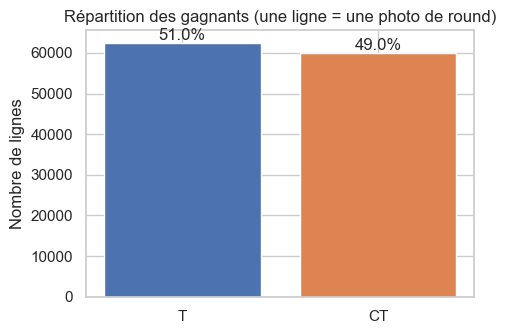

In [8]:
counts = df["round_winner"].value_counts()
share = df["round_winner"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=["#4C72B0", "#DD8452"])
for bar, s in zip(bars, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{s:.1%}",
            ha="center", va="bottom")
ax.set_title("Répartition des gagnants (une ligne = une photo de round)")
ax.set_ylabel("Nombre de lignes")
plt.tight_layout()
plt.show()

## 7. Doublons

Certaines lignes sont strictement identiques. C'est attendu : au tout début d'un round, plusieurs photos successives peuvent montrer exactement le même état (personne n'a encore bougé ni acheté).

On **ne les supprime pas maintenant**. À l'étape 3, on reconstruira les rounds : on pourra alors décider proprement quoi en faire, sans casser la structure des rounds.

In [9]:
dup_mask = df.duplicated(keep=False)
print(f"Lignes impliquées dans un doublon : {dup_mask.sum():,}")
df.loc[dup_mask, main_cols + ["map", "round_winner"]].head(10)

Lignes impliquées dans un doublon : 6,904


,time_left,ct_score,t_score,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_players_alive,t_players_alive,map,round_winner
0,175.00,0.0,0.0,500.0,500.0,0.0,0.0,4000.0,4000.0,5.0,5.0,de_dust2,CT
190,170.00,7.0,8.0,500.0,500.0,200.0,200.0,2000.0,300.0,5.0,5.0,de_mirage,CT
191,170.00,7.0,8.0,500.0,500.0,200.0,200.0,2000.0,300.0,5.0,5.0,de_mirage,CT
278,169.96,0.0,0.0,500.0,500.0,0.0,0.0,4000.0,4000.0,5.0,5.0,de_dust2,CT
383,170.00,11.0,4.0,500.0,500.0,200.0,300.0,1900.0,650.0,5.0,5.0,de_dust2,T
384,170.00,11.0,4.0,500.0,500.0,200.0,300.0,1900.0,650.0,5.0,5.0,de_dust2,T
385,170.00,11.0,4.0,500.0,500.0,200.0,300.0,1900.0,650.0,5.0,5.0,de_dust2,T
475,175.00,0.0,0.0,500.0,500.0,0.0,0.0,4000.0,4000.0,5.0,5.0,de_nuke,CT
628,174.92,0.0,0.0,500.0,500.0,0.0,0.0,4000.0,4000.0,5.0,5.0,de_inferno,T
736,175.00,8.0,7.0,500.0,500.0,100.0,300.0,3350.0,650.0,5.0,5.0,de_inferno,CT


## 8. Conclusion de l'étape 1

- Le dataset contient **122 410 lignes** et **98 colonnes** (dont la cible `t_win`), sur **8 cartes**.
- Valeurs manquantes : **aucune**.
- Lignes en double : **4 962 (4,1 %)**. Elles sont gardées pour l'instant : on les traitera à l'étape 3, après la reconstruction des rounds.
- Répartition de la cible : **51,0 % de victoires T** et **49,0 % de victoires CT**. Le dataset est équilibré, donc l'accuracy reste lisible, mais on utilisera aussi d'autres métriques.
- Anomalie détectée : **N lignes** ont 6 joueurs T vivants (et une santé T jusqu'à 600), alors qu'une équipe a 5 joueurs maximum. Ces lignes seront traitées à l'étape 3.

**Prochaine étape :** analyse exploratoire (EDA).